In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
student_info = pd.read_csv("studentInfo.csv")

student_vle = pd.read_csv("studentVle.csv")

In [3]:
student_info.shape

(32593, 12)

In [4]:
student_vle.shape

(10655280, 6)

In [5]:
student_info.columns

Index(['code_module', 'code_presentation', 'id_student', 'gender', 'region',
       'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts',
       'studied_credits', 'disability', 'final_result'],
      dtype='str')

In [6]:
student_vle.columns

Index(['code_module', 'code_presentation', 'id_student', 'id_site', 'date',
       'sum_click'],
      dtype='str')

In [7]:
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [8]:
student_vle.head()

,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [9]:
student_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   code_module           32593 non-null  str  
 1   code_presentation     32593 non-null  str  
 2   id_student            32593 non-null  int64
 3   gender                32593 non-null  str  
 4   region                32593 non-null  str  
 5   highest_education     32593 non-null  str  
 6   imd_band              31482 non-null  str  
 7   age_band              32593 non-null  str  
 8   num_of_prev_attempts  32593 non-null  int64
 9   studied_credits       32593 non-null  int64
 10  disability            32593 non-null  str  
 11  final_result          32593 non-null  str  
dtypes: int64(3), str(9)
memory usage: 3.0 MB


In [10]:
student_vle.info()

<class 'pandas.DataFrame'>
RangeIndex: 10655280 entries, 0 to 10655279
Data columns (total 6 columns):
 #   Column             Dtype
---  ------             -----
 0   code_module        str  
 1   code_presentation  str  
 2   id_student         int64
 3   id_site            int64
 4   date               int64
 5   sum_click          int64
dtypes: int64(4), str(2)
memory usage: 487.8 MB


In [11]:
student_info.isnull().sum()

code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

In [12]:
student_vle.isnull().sum()

code_module          0
code_presentation    0
id_student           0
id_site              0
date                 0
sum_click            0
dtype: int64

In [13]:
student_info.describe()

,id_student,num_of_prev_attempts,studied_credits
count,3.259300e+04,32593.000000,32593.000000
mean,7.066877e+05,0.163225,79.758691
std,5.491673e+05,0.479758,41.071900
min,3.733000e+03,0.000000,30.000000
25%,5.085730e+05,0.000000,60.000000
50%,5.903100e+05,0.000000,60.000000
75%,6.444530e+05,0.000000,120.000000
max,2.716795e+06,6.000000,655.000000


In [14]:
student_vle.describe()

,id_student,id_site,date,sum_click
count,1.065528e+07,1.065528e+07,1.065528e+07,1.065528e+07
mean,7.333336e+05,7.383234e+05,9.517400e+01,3.716946e+00
std,5.827060e+05,1.312196e+05,7.607130e+01,8.849047e+00
min,6.516000e+03,5.267210e+05,-2.500000e+01,1.000000e+00
25%,5.077430e+05,6.735190e+05,2.500000e+01,1.000000e+00
50%,5.882360e+05,7.300690e+05,8.600000e+01,2.000000e+00
75%,6.464840e+05,8.770300e+05,1.560000e+02,3.000000e+00
max,2.698588e+06,1.049562e+06,2.690000e+02,6.977000e+03


data quality analysis

In [15]:
# Duplicate rows in student_info
student_info.duplicated().sum()

np.int64(0)

In [16]:
# Duplicate rows in student_vle
student_vle.duplicated().sum()

np.int64(787170)

In [17]:
duplicate_rows = student_vle[
    student_vle.duplicated()
]

duplicate_rows.head()

,code_module,code_presentation,id_student,id_site,date,sum_click
2,AAA,2013J,28400,546652,-10,1
63,AAA,2013J,45462,546652,-10,1
180,AAA,2013J,77367,546652,-10,4
193,AAA,2013J,94961,546652,-10,2
442,AAA,2013J,248270,546652,-10,4


In [18]:
duplicate_percentage = (
    len(duplicate_rows)
    / len(student_vle)
) * 100

duplicate_percentage

7.387605018357096

In [19]:
student_vle.columns

Index(['code_module', 'code_presentation', 'id_student', 'id_site', 'date',
       'sum_click'],
      dtype='str')

In [20]:
student_vle.duplicated(
    subset=[
        "id_student",
        "id_site",
        "date",
        "sum_click"
    ]
).sum()

np.int64(787170)

In [21]:
student_vle.shape

(10655280, 6)

In [22]:
student_vle_clean = (
    student_vle
    .drop_duplicates()
)

In [23]:
student_vle_clean.shape

(9868110, 6)

In [24]:
student_vle = (
    student_vle
    .drop_duplicates()
    .reset_index(drop=True)
)

In [25]:
student_vle.duplicated().sum()

np.int64(0)

student_vle contained a lot of duplicate rows...they were removed to avoid discrepencies during feature engineering

missing value analysis

In [26]:
def missing_percentage(df):

    missing = (
        df.isnull()
        .sum()
        .sort_values(ascending=False)
    )

    percentage = (
        (missing / len(df)) * 100
    )

    missing_df = pd.DataFrame({
        "Missing Values": missing,
        "Percentage": percentage
    })

    return missing_df

In [27]:
missing_percentage(student_info)

,Missing Values,Percentage
imd_band,1111,3.408707
code_module,0,0.000000
id_student,0,0.000000
code_presentation,0,0.000000
gender,0,0.000000
region,0,0.000000
highest_education,0,0.000000
age_band,0,0.000000
num_of_prev_attempts,0,0.000000
studied_credits,0,0.000000


In [28]:
missing_percentage(student_vle)

,Missing Values,Percentage
code_module,0,0.0
code_presentation,0,0.0
id_student,0,0.0
id_site,0,0.0
date,0,0.0
sum_click,0,0.0


above step is done to check for missing values and to decide whether to drop or impute them

TARGET VARIABLE

In [29]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [30]:
(
    student_info["final_result"]
    .value_counts(normalize=True)
    * 100
)

final_result
Pass           37.925321
Withdrawn      31.160065
Fail           21.636548
Distinction     9.278066
Name: proportion, dtype: float64

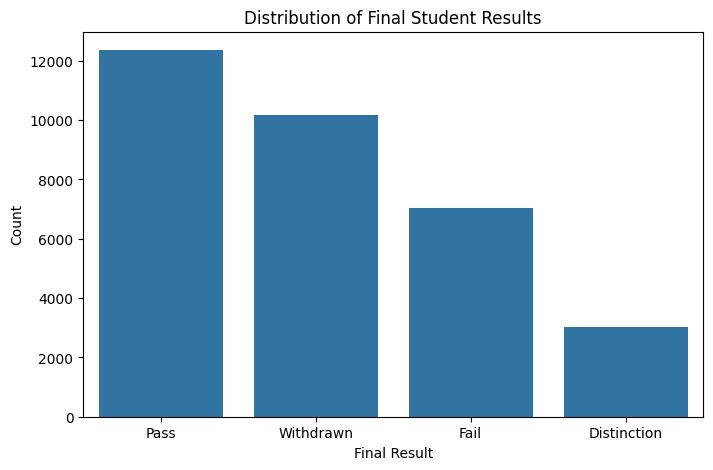

In [31]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=student_info,
    x="final_result"
)

plt.title("Distribution of Final Student Results")

plt.xlabel("Final Result")

plt.ylabel("Count")

plt.show()

STUDENT DEMOGRAPHICS

In [32]:
student_info["age_band"].value_counts()

age_band
0-35     22944
35-55     9433
55<=       216
Name: count, dtype: int64

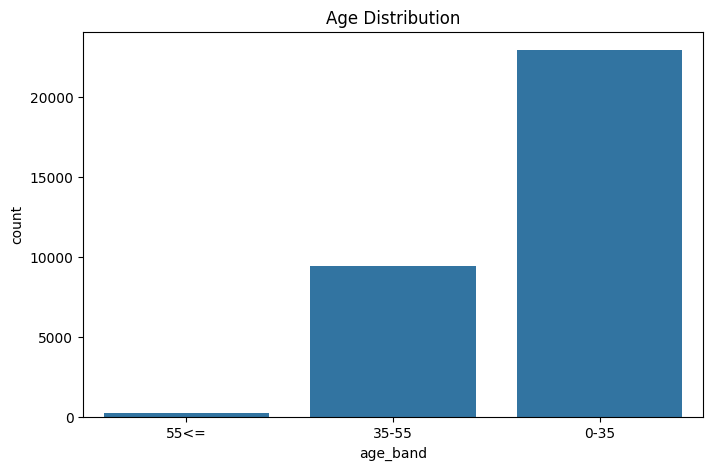

In [33]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=student_info,
    x="age_band"
)

plt.title("Age Distribution")

plt.show()

In [34]:
student_info["highest_education"].value_counts()

highest_education
A Level or Equivalent          14045
Lower Than A Level             13158
HE Qualification                4730
No Formal quals                  347
Post Graduate Qualification      313
Name: count, dtype: int64

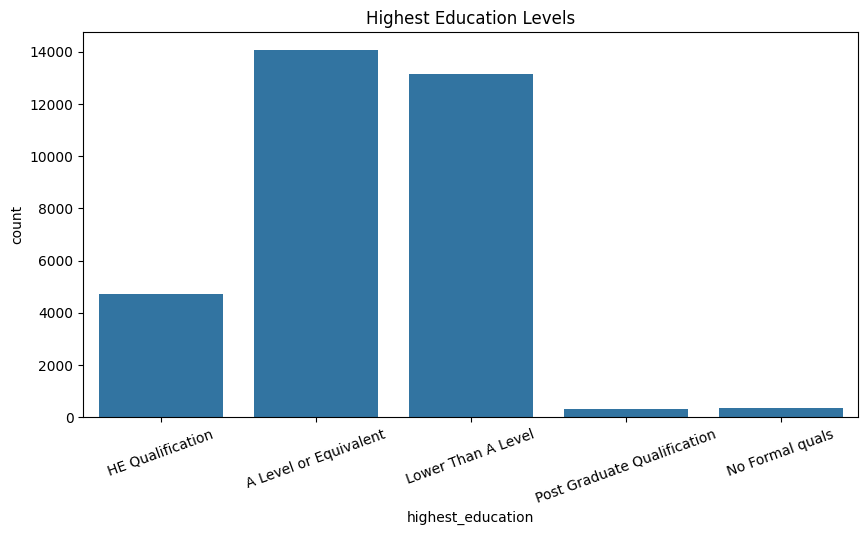

In [35]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=student_info,
    x="highest_education"
)

plt.xticks(rotation=20)

plt.title("Highest Education Levels")

plt.show()

ENGAGEMENT ANALYTICS

In [36]:
total_clicks = (
    student_vle
    .groupby("id_student")["sum_click"]
    .sum()
    .reset_index()
)

total_clicks.columns = [
    "id_student",
    "total_clicks"
]

In [37]:
total_clicks.head()

,id_student,total_clicks
0,6516,2715
1,8462,643
2,11391,922
3,23629,153
4,23698,886


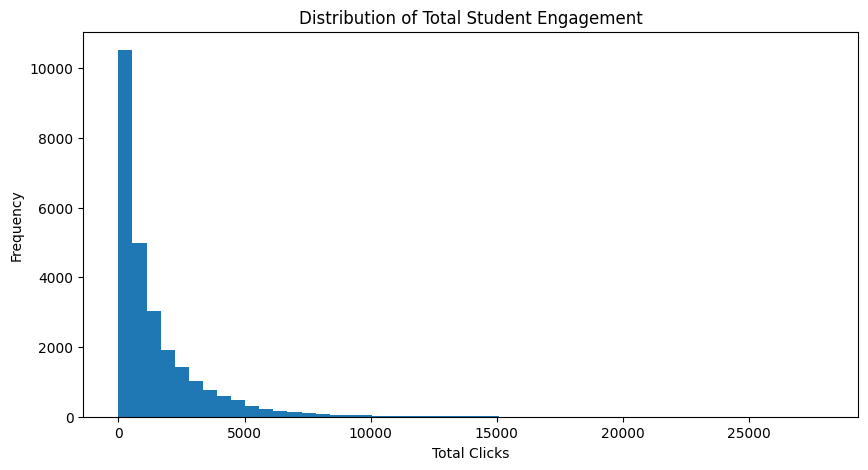

In [38]:
plt.figure(figsize=(10,5))

plt.hist(
    total_clicks["total_clicks"],
    bins=50
)

plt.title("Distribution of Total Student Engagement")

plt.xlabel("Total Clicks")

plt.ylabel("Frequency")

plt.show()

ACTIVE DAYS

In [39]:
active_days = (
    student_vle
    .groupby("id_student")["date"]
    .nunique()
    .reset_index()
)

active_days.columns = [
    "id_student",
    "active_days"
]

In [40]:
active_days.head()

,id_student,active_days
0,6516,159
1,8462,56
2,11391,40
3,23629,16
4,23698,70


MERGING OF FEATURES

In [41]:
student_features = (
    student_info
    .merge(
        total_clicks,
        on="id_student",
        how="left"
    )
    .merge(
        active_days,
        on="id_student",
        how="left"
    )
)

In [42]:
student_features.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,active_days
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,922.0,40.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1409.0,80.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,260.0,12.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,2007.0,123.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1012.0,70.0


In [43]:
student_features["avg_daily_clicks"] = (
    student_features["total_clicks"]
    /
    student_features["active_days"]
)

In [44]:
student_features[
    [
        "id_student",
        "total_clicks",
        "active_days",
        "avg_daily_clicks"
    ]
].head()

,id_student,total_clicks,active_days,avg_daily_clicks
0,11391,922.0,40.0,23.050000
1,28400,1409.0,80.0,17.612500
2,30268,260.0,12.0,21.666667
3,31604,2007.0,123.0,16.317073
4,32885,1012.0,70.0,14.457143


ENGAGEMENT VS PERFORMANCE

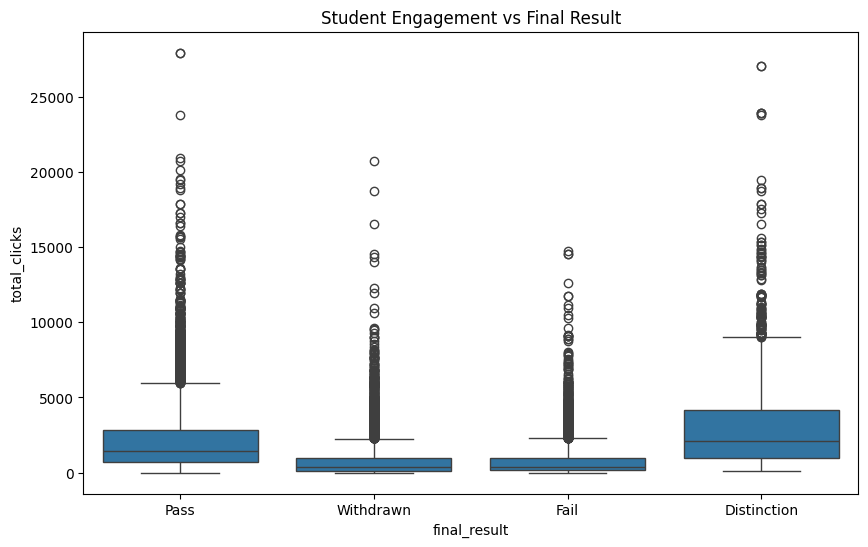

In [45]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=student_features,
    x="final_result",
    y="total_clicks"
)

plt.title(
    "Student Engagement vs Final Result"
)

plt.show()

active days vs performanc

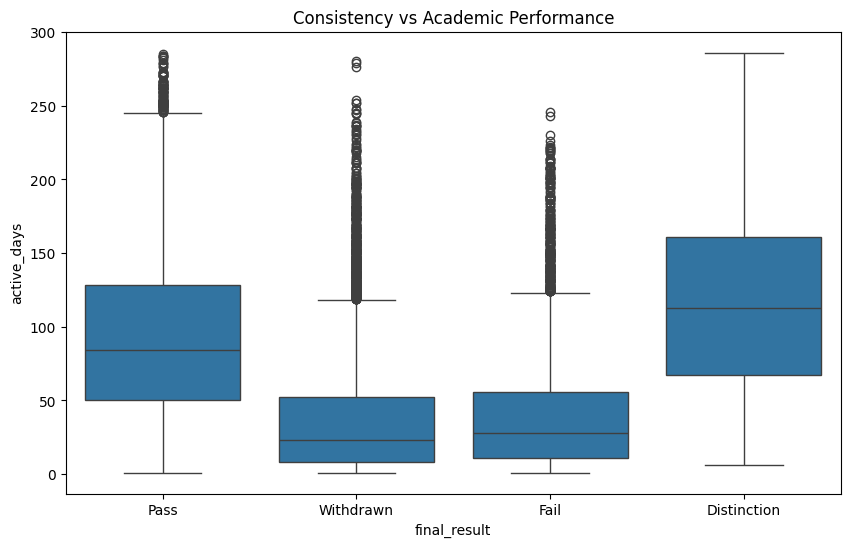

In [46]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=student_features,
    x="final_result",
    y="active_days"
)

plt.title(
    "Consistency vs Academic Performance"
)

plt.show()

OUTLIER ANALYSIS

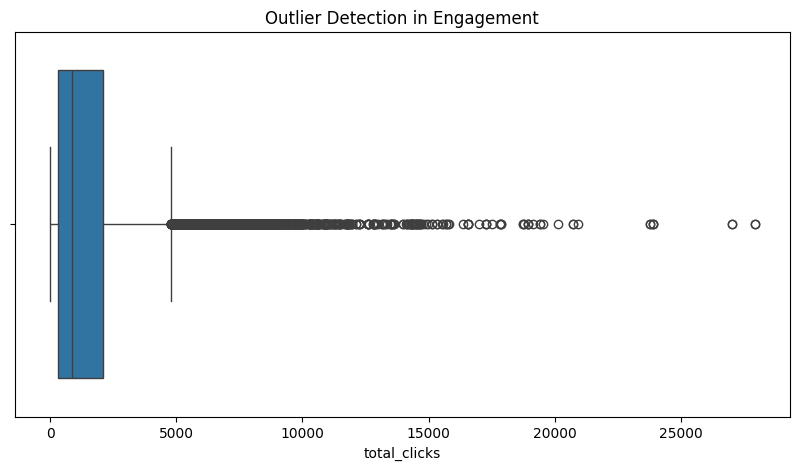

In [47]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=student_features["total_clicks"]
)

plt.title("Outlier Detection in Engagement")

plt.show()

CORRELATION ANALYSIS

In [48]:
numeric_columns = [
    "studied_credits",
    "total_clicks",
    "active_days",
    "avg_daily_clicks"
]

In [49]:
correlation_matrix = (
    student_features[numeric_columns]
    .corr()
)

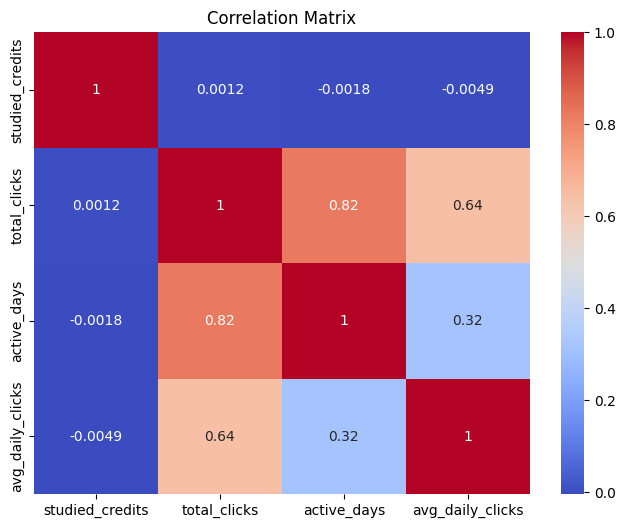

In [50]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

In [81]:
import os

os.makedirs(
    "data/processed",
    exist_ok=True
)

student_features.to_csv(
    "data/processed/student_features_advanced.csv",
    index=False
)

ADVANCED FEATURE ENGINEERING

we will now create behavioural metrics,temporal features and engagement intelligence

In [52]:
daily_clicks = (
    student_vle
    .groupby(
        ["id_student", "date"]
    )["sum_click"]
    .sum()
    .reset_index()
)

In [53]:
daily_clicks.head()

,id_student,date,sum_click
0,6516,-23,28
1,6516,-22,82
2,6516,-20,41
3,6516,-17,7
4,6516,-12,2


this is the engagement span

In [54]:
engagement_span = (
    daily_clicks
    .groupby("id_student")["date"]
    .agg(["min", "max"])
    .reset_index()
)

In [55]:
engagement_span.columns = [
    'id_student','first_active_day','last_active_day'
]

In [56]:
engagement_span.head()

,id_student,first_active_day,last_active_day
0,6516,-23,269
1,8462,-6,118
2,11391,-5,253
3,23629,-6,87
4,23698,-18,231


In [57]:
engagement_span["engagement_span_days"] = (
    engagement_span["last_active_day"]-engagement_span["first_active_day"]
)

the above cell measures how long the student stayed academically active

now we will measure how consistently students studied during their active period

In [58]:
student_features = (
    student_features
    .merge(
        engagement_span[
            [
                "id_student",
                "engagement_span_days"
            ]
        ],
        on="id_student",
        how="left"
    )
)

In [59]:
student_features['activity_density']=student_features['active_days']/student_features['engagement_span_days']

In [60]:
click_std = (
    daily_clicks
    .groupby("id_student")["sum_click"]
    .std()
    .reset_index()
)

In [61]:
click_std.columns = [
    "id_student",
    "click_std"
]

In [62]:
student_features = (
    student_features
    .merge(
        click_std,
        on="id_student",
        how="left"
    )
)

the mean daily clicks

In [63]:
daily_mean = (
    daily_clicks
    .groupby("id_student")["sum_click"]
    .mean()
    .reset_index()
)

In [64]:
daily_mean.columns = [
    "id_student",
    "daily_click_mean"
]

In [65]:
student_features = (
    student_features
    .merge(
        daily_mean,
        on="id_student",
        how="left"
    )
)

In [66]:
student_features["click_cv"] = (
    student_features["click_std"]
    /
    student_features["daily_click_mean"]
)

now resource diversity

In [67]:
unique_sites = (
    student_vle
    .groupby("id_student")["id_site"]
    .nunique()
    .reset_index()
)

In [68]:
unique_sites.columns = [
    "id_student",
    "unique_sites_visited"
]

In [69]:
student_features = (
    student_features
    .merge(
        unique_sites,
        on="id_student",
        how="left"
    )
)

now early mid and late engagement

In [ ]:
early_clicks = (
    student_vle[  #early phase
        student_vle["date"] <= 60
    ]
    .groupby("id_student")["sum_click"]
    .sum()
    .reset_index()
)

In [71]:
early_clicks.columns = [
    "id_student",
    "clicks_early"
]

In [ ]:
mid_clicks = (
    student_vle[
        (student_vle["date"] > 60)
        &
        (student_vle["date"] <= 180)  # mid phase
    ]
    .groupby("id_student")["sum_click"]
    .sum()
    .reset_index()
)

In [74]:
mid_clicks.columns = [
    "id_student",
    "clicks_mid"
]

In [75]:
# late phase
late_clicks = (
    student_vle[
        student_vle["date"] > 180
    ]
    .groupby("id_student")["sum_click"]
    .sum()
    .reset_index()
)

In [76]:
late_clicks.columns = [
    "id_student",
    "clicks_late"
]

In [77]:
student_features = (   #merging all of them
    student_features
    .merge(
        early_clicks,
        on="id_student",
        how="left"
    )
    .merge(
        mid_clicks,
        on="id_student",
        how="left"
    )
    .merge(
        late_clicks,
        on="id_student",
        how="left"
    )
)

In [ ]:
student_features["early_engagement_ratio"] = (   #the early engegement ratio
    student_features["clicks_early"]
    /
    student_features["total_clicks"]
)

In [79]:
student_features.isnull().sum()

code_module                   0
code_presentation             0
id_student                    0
gender                        0
region                        0
highest_education             0
imd_band                   1111
age_band                      0
num_of_prev_attempts          0
studied_credits               0
disability                    0
final_result                  0
total_clicks               2852
active_days                2852
avg_daily_clicks           2852
engagement_span_days       2852
activity_density           2852
click_std                  3482
daily_click_mean           2852
click_cv                   3482
unique_sites_visited       2852
clicks_early               2943
clicks_mid                 7815
clicks_late               12689
early_engagement_ratio     2943
dtype: int64

In [80]:
student_features = (
    student_features
    .fillna(0)
)